# Cvičenie 6

Priestorovo frekvenčné reprezentácie - Haarova a waveletova.

pip install PyWavelets - kniznica na prácu s waveletmi

Príklad: overenie vlastnej Haarovej transformácie a porovnanie waveletov pri aproximácii obrazu z K koeficientov.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
import ipywidgets as widgets
import skimage as sk
from skimage.metrics import peak_signal_noise_ratio as psnr

image = sk.img_as_float(sk.data.camera())     # 512 x 512, hodnoty v [0, 1]
WAVELETY = ["haar", "db4", "sym4", "bior2.2", "bior4.4"]

## 1. Vlastná Haarova transformácia

Z prednášky Číslicové spracovanie obrazu - Časť 5: Priestorovo-frekvenčná reprezentácia obrazu, doplňte funkciu **haar_krok_riadky**.

a[:, 0::2] - vybere z matice a iba párne stĺpce.

In [21]:
def haar_krok_riadky(img):
    s = np.sqrt(2) / 2
    p = img[:, 0::2]          # x(2n)   - párne stĺpce
    n = img[:, 1::2]          # x(2n+1) - nepárne stĺpce
    c = s * (p + n)           # aproximácia (priemer dvojice)
    d = s * (p - n)           # detail (rozdiel dvojice)
    return np.hstack([c, d])

def haar_krok_2d(img):
    y = haar_krok_riadky(img)
    y = haar_krok_riadky(y.T).T
    return y

def haar_2d(img, L):
    y = img.astype(float).copy()
    h, w = y.shape
    for _ in range(L):
        y[:h, :w] = haar_krok_2d(y[:h, :w])
        h, w = h // 2, w // 2
    return y

def ponechaj_K(y, K):
    """Ponechá K koeficientov s najväčšou absolútnou hodnotou, ostatné vynuluje."""
    prah = np.sort(np.abs(y).ravel())[-K]
    return np.where(np.abs(y) >= prah, y, 0)

Zobrazte Haarovu transformáciu najskor po riadkoch, potom jeden krok a nakoniec viacúrovňovú použitím funkcií vyššie.

Na zvýraznenie detailov možete použiť napríklad ekvalizáciu histogramu.

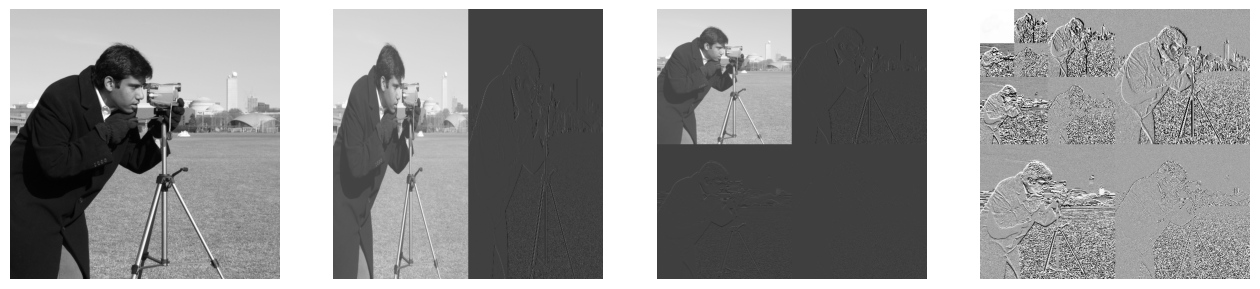

In [22]:
L = 3
po_riadkoch = haar_krok_riadky(image)          # 1. krok len po riadkoch
jeden_krok = haar_krok_2d(image)               # 1. krok po riadkoch aj stĺpcoch
viacurovnova = haar_2d(image, L)               # L úrovní

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(image, cmap="gray"); ax[0].axis("off")
ax[1].imshow(po_riadkoch, cmap="gray"); ax[1].axis("off")
ax[2].imshow(jeden_krok, cmap="gray"); ax[2].axis("off")
# detaily sú veľmi malé oproti aproximácii, preto ekvalizácia histogramu
ax[3].imshow(sk.exposure.equalize_hist(viacurovnova), cmap="gray"); ax[3].axis("off")
plt.show()

## 2. Overenie: pywt vs. vlastná implementácia


Porovnajte pomocou **np.allclose** implementaciu z predošlého kroku s implementáciou knižnice pywt.

pywt.wavedec2(image, "haar", mode="periodization", level=L)

`mode="periodization"` zodpovedá periodickému rozšíreniu z prednášky (indexy modulo $N_l$), takže každé pásmo má presne polovičný rozmer.


pywt.coeffs_to_array(coeffs) - slúži na prevod koeficientov

In [23]:
L = 3
coeffs = pywt.wavedec2(image, "haar", mode="periodization", level=L)
arr, slices = pywt.coeffs_to_array(coeffs)    # zoznam pásiem -> jedna matica

print("tvar spektra:", arr.shape)
print("vlastná Haarova DWT == pywt:", np.allclose(haar_2d(image, L), arr))

tvar spektra: (512, 512)
vlastná Haarova DWT == pywt: True


## 3. Porovnanie waveletov pri pevnom K

Doplňte funkciu approximuj aby v array spektra nechala iba K koeficientov. 
Použite funkcie: pywt.wavedec2, pywt.coeffs_to_array, ponechaj_K, pywt.array_to_coeffs, pywt.waverec2.

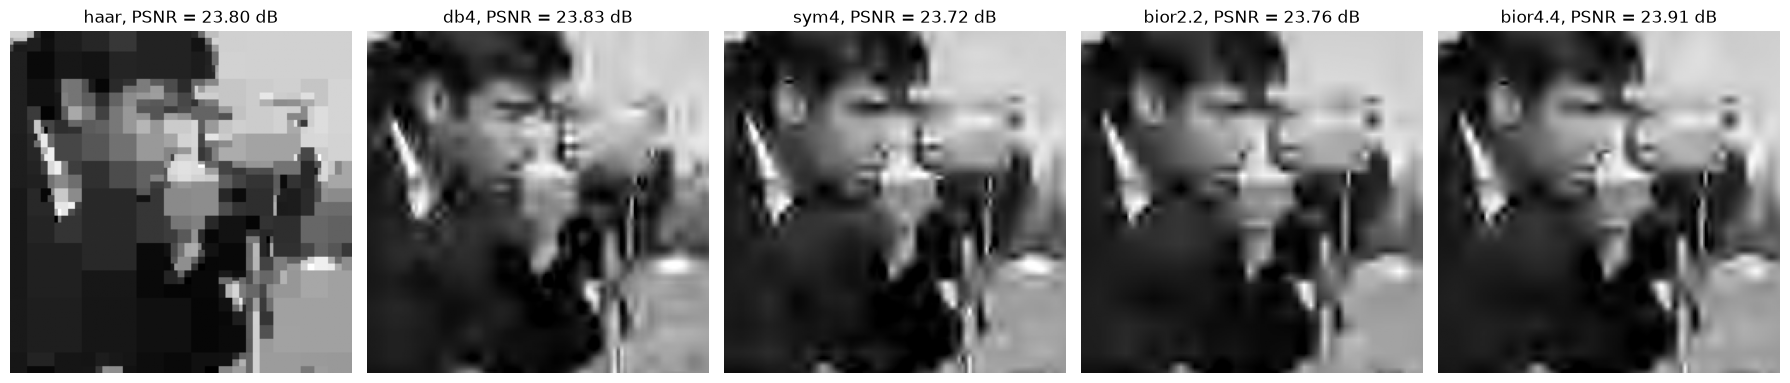

In [28]:
def aproximuj(img, wavelet, L, K):
    coeffs = pywt.wavedec2(img, wavelet, mode="periodization", level=L)
    arr, slices = pywt.coeffs_to_array(coeffs)
    arr = ponechaj_K(arr, K)                                   # ponechaj len K najväčších
    coeffs = pywt.array_to_coeffs(arr, slices, output_format="wavedec2")
    return pywt.waverec2(coeffs, wavelet, mode="periodization")

L, K = 5, 1000
vyrez = (slice(100, 300), slice(150, 350))     # detail tváre a kamery

fig, ax = plt.subplots(1, len(WAVELETY), figsize=(18, 4))
for a, nazov in zip(ax, WAVELETY):
    rec = aproximuj(image, nazov, L, K)
    a.imshow(rec[vyrez], cmap="gray", vmin=0, vmax=1)
    a.set_title(f"{nazov}, PSNR = {psnr(image, np.clip(rec, 0, 1), data_range=1):.2f} dB")
    a.axis("off")
plt.tight_layout()
plt.show()

## 4. Interaktívne porovnanie

pip install ipywidgets - kniznica na interaktivne widgety

In [25]:
def zobraz(wavelet, L, K):
    rec = aproximuj(image, wavelet, L, int(K))
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(rec, cmap="gray", vmin=0, vmax=1)
    ax[0].set_title(f"{wavelet}, L = {L}, K = {int(K)}, "
                    f"PSNR = {psnr(image, np.clip(rec, 0, 1), data_range=1):.2f} dB")
    ax[1].imshow(rec[vyrez], cmap="gray", vmin=0, vmax=1)
    ax[1].set_title("výrez")
    for a in ax:
        a.axis("off")
    plt.show()

widgets.interact(
    zobraz,
    wavelet=widgets.Dropdown(options=WAVELETY, value="haar"),
    L=widgets.IntSlider(value=4, min=1, max=6, continuous_update=False),
    K=widgets.FloatLogSlider(value=1000, base=10, min=2, max=np.log10(image.size),
                             continuous_update=False),
);

interactive(children=(Dropdown(description='wavelet', options=('haar', 'db4', 'sym4', 'bior2.2', 'bior4.4'), v…

## Filtre waveletov

DWT je filtrácia dvojicou filtrov $h$ (DP) a $g$ (HP) nasledovaná decimáciou.

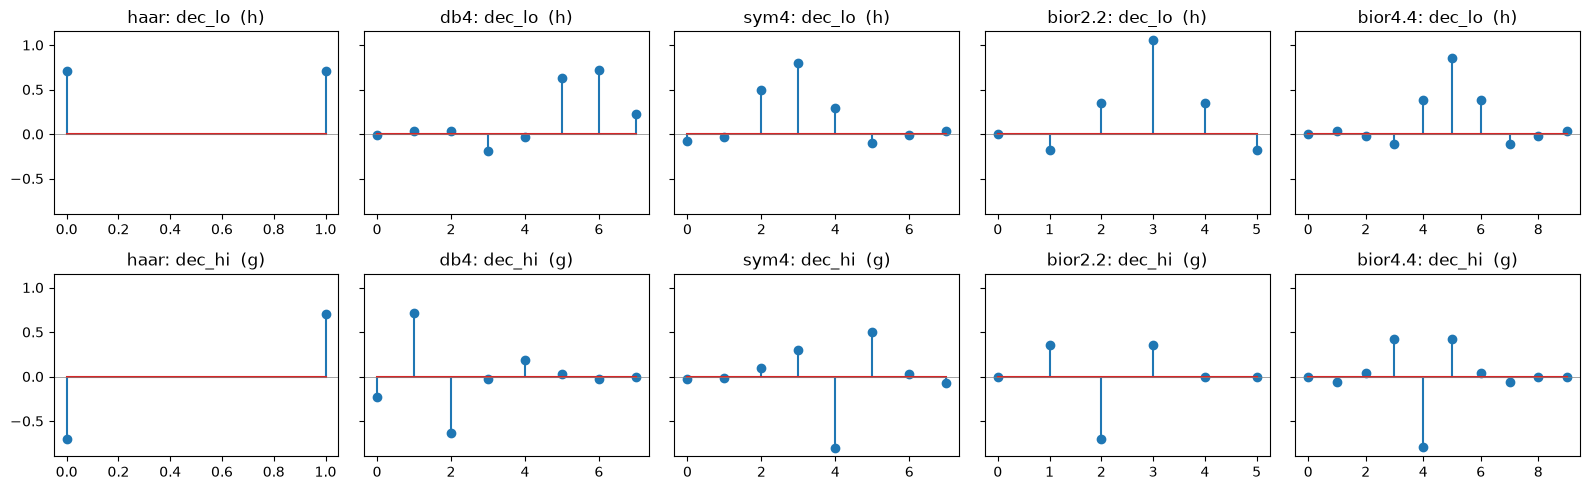

haar dec_lo: [0.7071067811865476, 0.7071067811865476]
haar dec_hi: [-0.7071067811865476, 0.7071067811865476]


In [26]:
fig, ax = plt.subplots(2, len(WAVELETY), figsize=(16, 5), sharey=True)
for j, nazov in enumerate(WAVELETY):
    w = pywt.Wavelet(nazov)
    for i, (filtr, popis) in enumerate([(w.dec_lo, "dec_lo  (h)"), (w.dec_hi, "dec_hi  (g)")]):
        ax[i, j].stem(filtr)
        ax[i, j].axhline(0, color="gray", lw=0.5)
        ax[i, j].set_title(f"{nazov}: {popis}")
plt.tight_layout()
plt.show()

print("haar dec_lo:", pywt.Wavelet("haar").dec_lo)
print("haar dec_hi:", pywt.Wavelet("haar").dec_hi)